# ``meshlab`` - Tutorial 2

**Boundary layers around an L-shaped geometry**


## 1. Import packages
---


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from functions.create_polygon import create_polygon

from meshlab.core import Mesh, Curve, Contour, Front
from meshlab.operations import (
    insert_contour, initialize_front, compute_normals, advance_front,
    compute_angles, smooth_normals, find_short_edges, collapse_edges,
)
from meshlab.utils import plot_mesh

## 2. Geometries definition
---


L-shaped body


In [2]:
# Geometric parameters
vertices = np.array([
    [ 0.0,  0.0],
    [ 0.0,  1.0],
    [-0.5,  1.0],
    [-0.5, -1.0],
    [ 1.0, -1.0],
    [ 1.0,  0.0],
])
points_per_edge = 5

# Counter-clockwise direction
points = create_polygon(
    vertices=vertices,
    points_per_edge=[points_per_edge] * len(vertices),
)

# Close curve
points = np.vstack((points, points[0]))

# Define contour
surface = Contour("l_body", [Curve("wall", points)])

## 3. Layer parameters
---

In [3]:
num_layers = 3
height = 0.05
growth_rate = 1.10
smooth_steps = 5
relaxation = 1.0

## 4. Example 1
---

**Central normals without height correction**

Creating mesh and initializing front


In [4]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, surface)

# Front definition
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

Growing boundary layers


In [5]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="central")
    advance_front(mesh, front, normals, h)
    h *= growth_rate

Visualize mesh


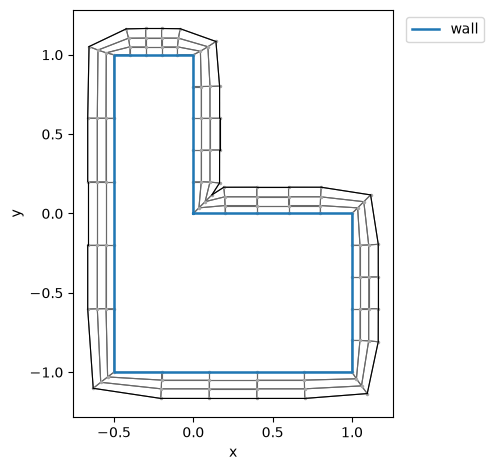

In [6]:
figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 5. Example 2
---

**Bisector normals with height correction**

Creating mesh and initializing front


In [7]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, surface)

# Front definition
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

Growing boundary layers


In [8]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")
    angles = compute_angles(mesh, front)
    heights = h / np.sin(angles / 2)
    advance_front(mesh, front, normals, heights)
    h *= growth_rate

Visualize mesh


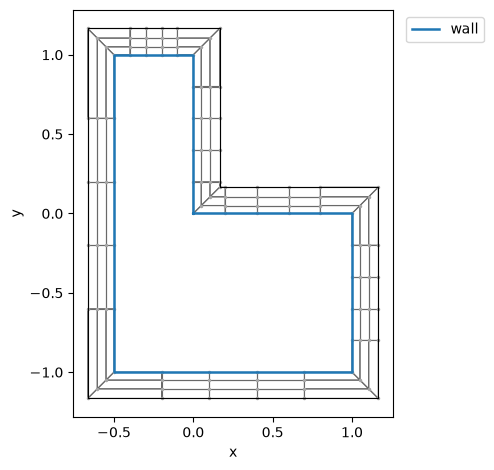

In [9]:
figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 6. Example 3
---

**Smoothed bisectors with height correction**

Creating mesh and initializing front


In [10]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, surface)

# Front definition
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

Growing boundary layers


In [11]:
h = height
for _ in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")

    rotation = np.zeros(len(normals), dtype=mesh.float_dtype)
    for _ in range(smooth_steps):
        normals, step_rotation = smooth_normals(mesh, front, normals, relaxation)
        rotation += step_rotation

    angles = compute_angles(mesh, front)

    # Height correction
    heights = h / np.sin(angles / 2 + np.abs(rotation))
    
    advance_front(mesh, front, normals, heights)
    h *= growth_rate

Visualize mesh


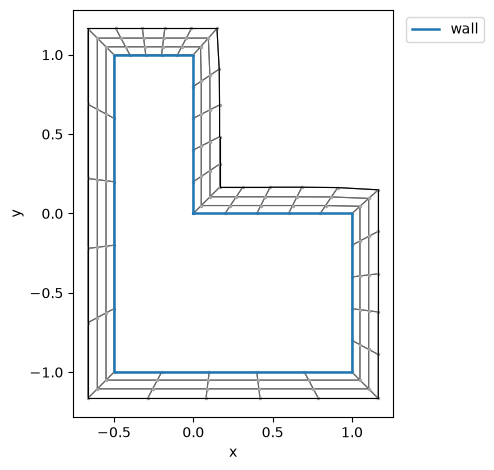

In [12]:
figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()

## 7. Example 4
---

**More layers with short-edge collapse**

Creating mesh and initializing front


In [13]:
# Layer parameters
num_layers = 10
height = 0.04
min_edge_ratio = 1.5

# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contour
insert_contour(mesh, surface)

# Front definition
front = Front("l_front", int_dtype=mesh.int_dtype)
initialize_front(mesh, front, curves=["wall"])

Growing boundary layers


In [14]:
h = height
total_collapsed = 0
for layer in range(num_layers):
    normals = compute_normals(mesh, front, method="bisector")
    angles = compute_angles(mesh, front)
    heights = h / np.sin(angles / 2)
    advance_front(mesh, front, normals, heights)

    edges = find_short_edges(mesh, front, min_edge_ratio * h)
    previous_count = len(front.entities.edge)
    # Update mesh, front and boundary indices in place
    index_map = collapse_edges(mesh, front, edges)

    collapsed = previous_count - len(front.entities.edge)
    total_collapsed += collapsed
    if collapsed:
        print(f"Layer {layer + 1}: {collapsed} collapsed edges.")
    h *= growth_rate

print(f"Total: {total_collapsed} collapsed edges.")

Layer 3: 2 collapsed edges.
Layer 6: 2 collapsed edges.
Layer 7: 3 collapsed edges.
Layer 9: 2 collapsed edges.
Total: 9 collapsed edges.


Visualize mesh


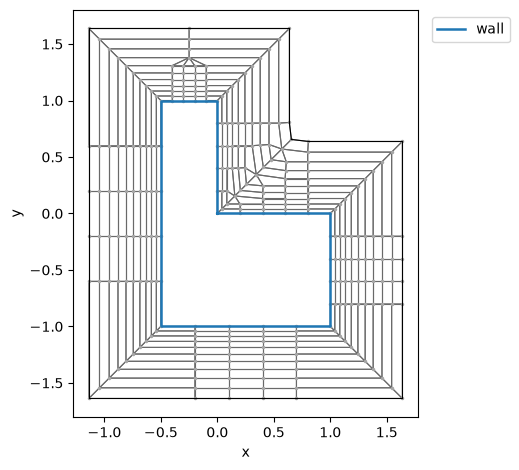

In [15]:
figure, ax = plot_mesh(mesh, show=False)

ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()